
# DSP, FFT & Wavelets Research Pipeline
### Spectral Analysis, Noise Quantification, Frequency-Domain Filtering, and Time-Frequency (Wavelet) Localization

**Author:** Kaveesha Induwara &nbsp;|&nbsp; Department of Physics, Faculty of Science, University of Colombo

---

**Scope.** This notebook processes five time-domain signals (`time_domain_signal1.csv` &ndash; `time_domain_signal5.csv`) through a complete DSP pipeline:

1. Tri-plot spectral visualization (time domain, continuous-style FFT envelope, discrete-style FFT stem) for each signal.
2. Automated noise-floor estimation and pre-filtering SNR (dB) quantification.
3. Frequency-domain masking and IFFT-based signal reconstruction, with post-filtering SNR and $\Delta \mathrm{SNR}$.
4. Wavelet theory (time-frequency localization) and a practical Continuous Wavelet Transform (CWT) scalogram analysis of Signals 4 and 5, which contain abrupt, non-stationary frequency transitions.

> **Note on source material.** A reference PDF titled *"Digital Signal Processing: Wavelets"* was referenced for Section 4 but was not available in this environment at notebook-build time. Section 4's theory is therefore drawn from standard DSP/wavelet literature (Mallat, *A Wavelet Tour of Signal Processing*; Daubechies, *Ten Lectures on Wavelets*) rather than quoted from that specific document. If you supply the PDF, re-run Section 4 with its content substituted in.

> **Note on sampling rate.** The CSVs carry no explicit time axis or sampling-rate metadata. Inspecting Signals 1&ndash;3 shows they complete *exactly* 5 and 12 full cycles over their 501-sample record respectively — the signature of a synthetically generated, integer-cycle teaching dataset. We therefore treat the record length as exactly **1 second**, giving an inferred sampling frequency of
> $$F_s = N_{\text{base}} = 501\ \text{Hz}, \qquad N_{\text{base}} = 501$$
> Signals 4 and 5 (1002 samples) are two such 1-second segments concatenated back-to-back (a 2-second, piecewise-stationary record), which is exactly the kind of abrupt frequency-step signal that breaks the FFT's time-locality assumption. **If you know the true acquisition sampling rate, change `FS_BASE` in the Setup cell below** — every downstream calculation (frequencies, SNR, filtering, CWT) is parameterized on it.


## 1. Setup & Data Loading

In [1]:

import numpy as np
import scipy.fft as sfft
from scipy.signal import find_peaks
import pywt
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams['figure.dpi'] = 110
mpl.rcParams['axes.titleweight'] = 'bold'
mpl.rcParams['font.size'] = 10

# ---- Inferred sampling configuration (see note above) ----
FS_BASE = 501.0          # Hz, inferred sampling frequency for the 501-sample base record
SIGNAL_FILES = {
    "Signal 1": "time_domain_signal1.csv",
    "Signal 2": "time_domain_signal2.csv",
    "Signal 3": "time_domain_signal3.csv",
    "Signal 4": "time_domain_signal4.csv",
    "Signal 5": "time_domain_signal5.csv",
}

def load_signal(path):
    """Load a single-row (or single-column) time-domain CSV as a 1-D float array."""
    data = np.loadtxt(path, delimiter=",")
    return np.asarray(data, dtype=float).ravel()

signals = {name: load_signal(fname) for name, fname in SIGNAL_FILES.items()}

for name, x in signals.items():
    fs = FS_BASE  # all signals share the same inferred per-sample rate
    dur = len(x) / fs
    print(f"{name:10s}  N={len(x):5d} samples   Fs={fs:.1f} Hz   duration={dur:.3f} s   "
          f"range=[{x.min():+.3f}, {x.max():+.3f}]")


Signal 1    N=  501 samples   Fs=501.0 Hz   duration=1.000 s   range=[-1.000, +1.000]
Signal 2    N=  501 samples   Fs=501.0 Hz   duration=1.000 s   range=[-0.500, +0.500]
Signal 3    N=  501 samples   Fs=501.0 Hz   duration=1.000 s   range=[-1.492, +1.492]
Signal 4    N= 1002 samples   Fs=501.0 Hz   duration=2.000 s   range=[-1.000, +1.000]
Signal 5    N= 1002 samples   Fs=501.0 Hz   duration=2.000 s   range=[-1.000, +1.000]



## 2. Tri-Plot Spectral Visualization Suite

For each signal we build a 3-row figure:

1. **Time domain** — amplitude vs. time (seconds).
2. **Continuous-style FFT amplitude spectrum** — a connected line plot through the single-sided amplitude spectrum, approximating the envelope of the underlying continuous spectrum.
3. **Discrete-style FFT amplitude spectrum** — a `stem` plot showing the *true* discrete frequency bins ($\Delta f = F_s/N$), which is what the DFT actually computes.

The single-sided amplitude spectrum is obtained via `scipy.fft.rfft`, normalized by $N$, and doubled (except at DC and Nyquist) to recover the physical sinusoid amplitude:

$$X[k] = \frac{2}{N}\left|\mathrm{FFT}\{x[n]\}[k]\right|, \qquad k = 0, 1, \dots, N/2$$


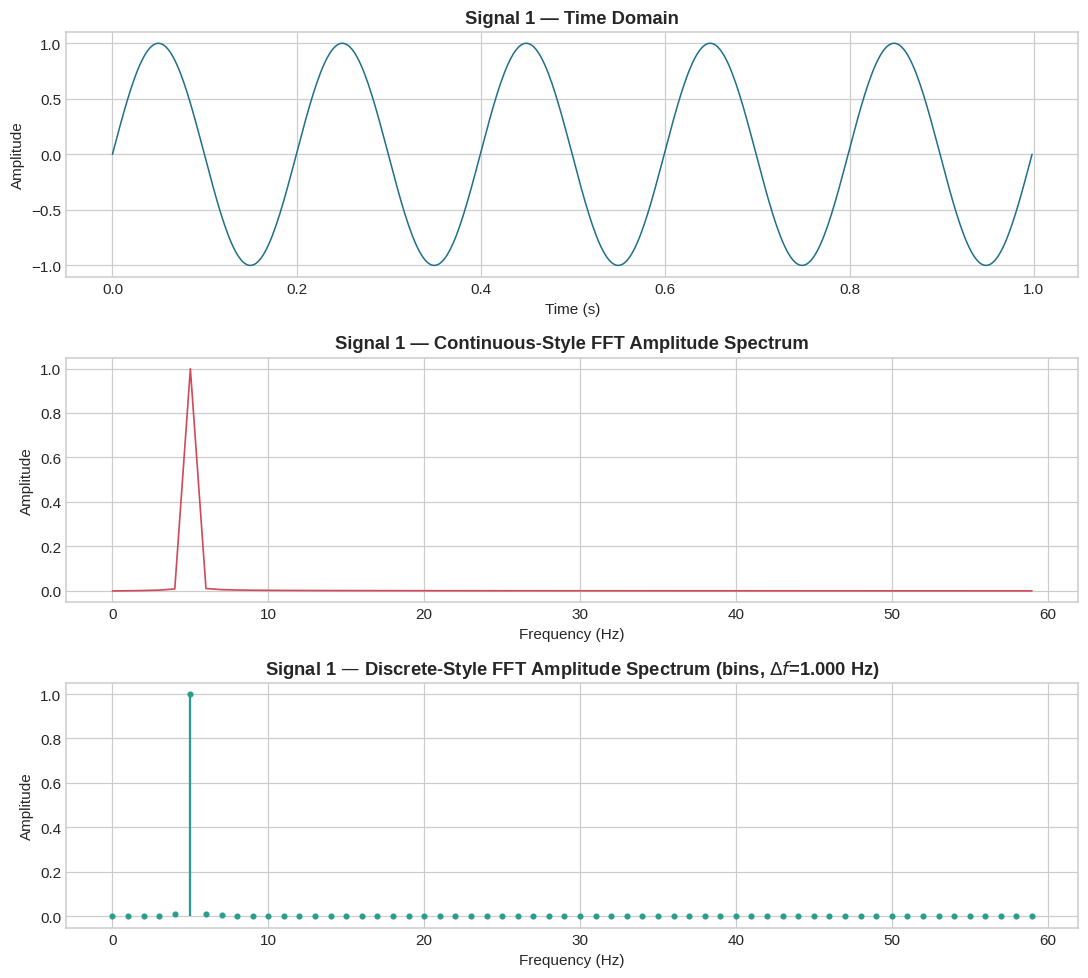

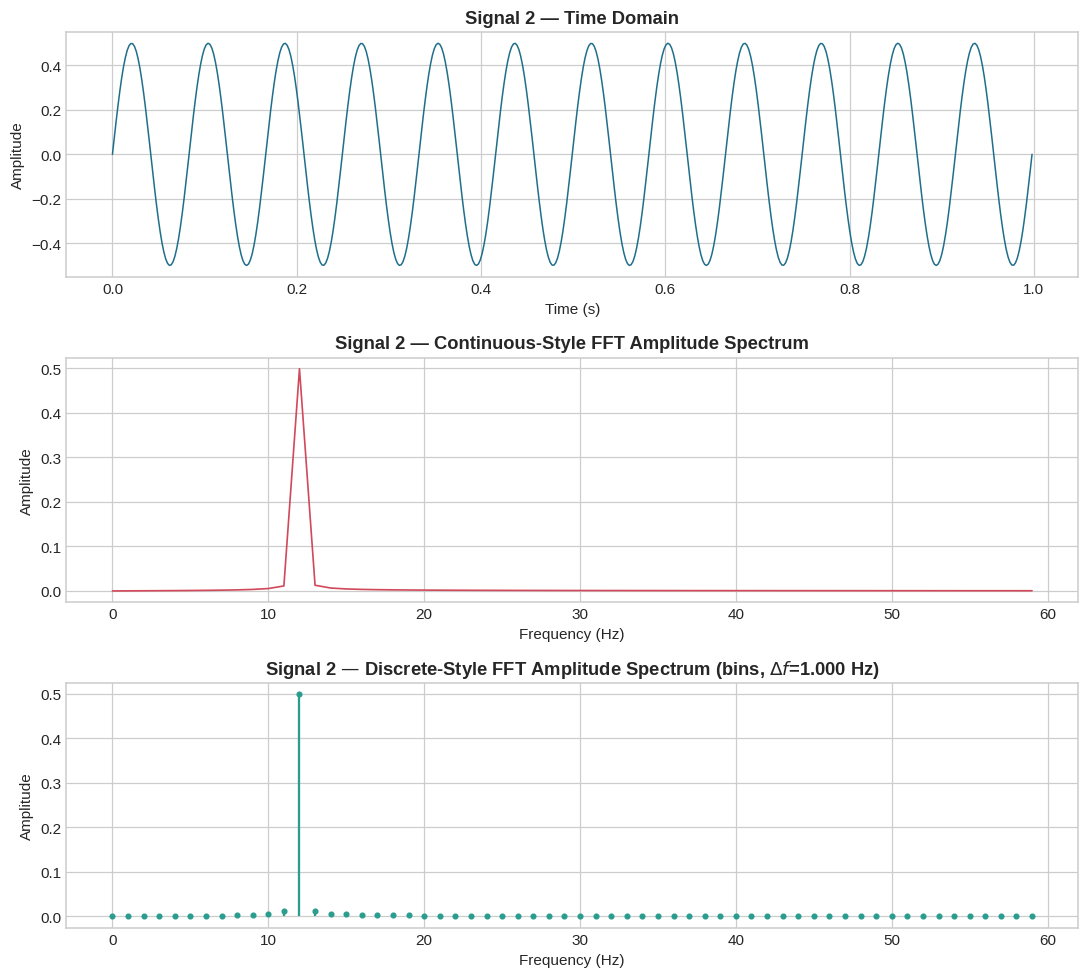

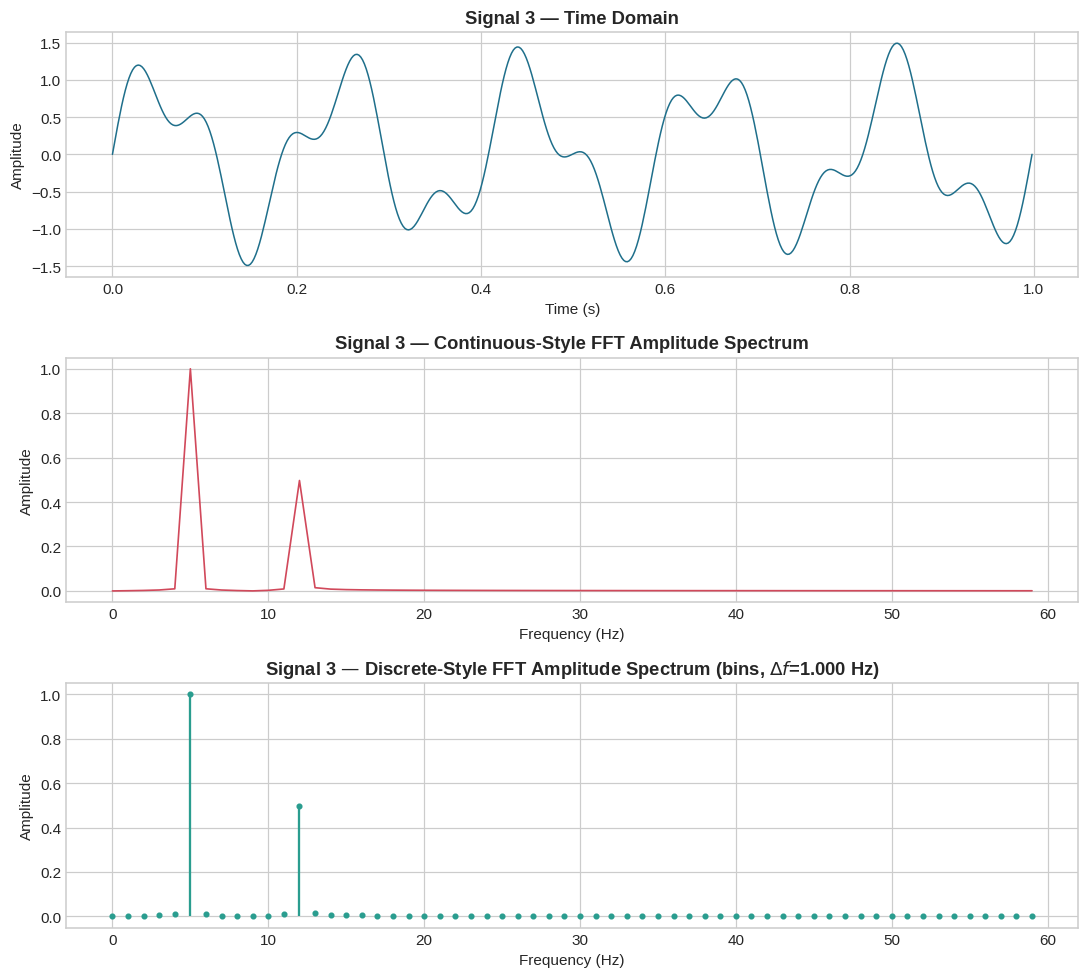

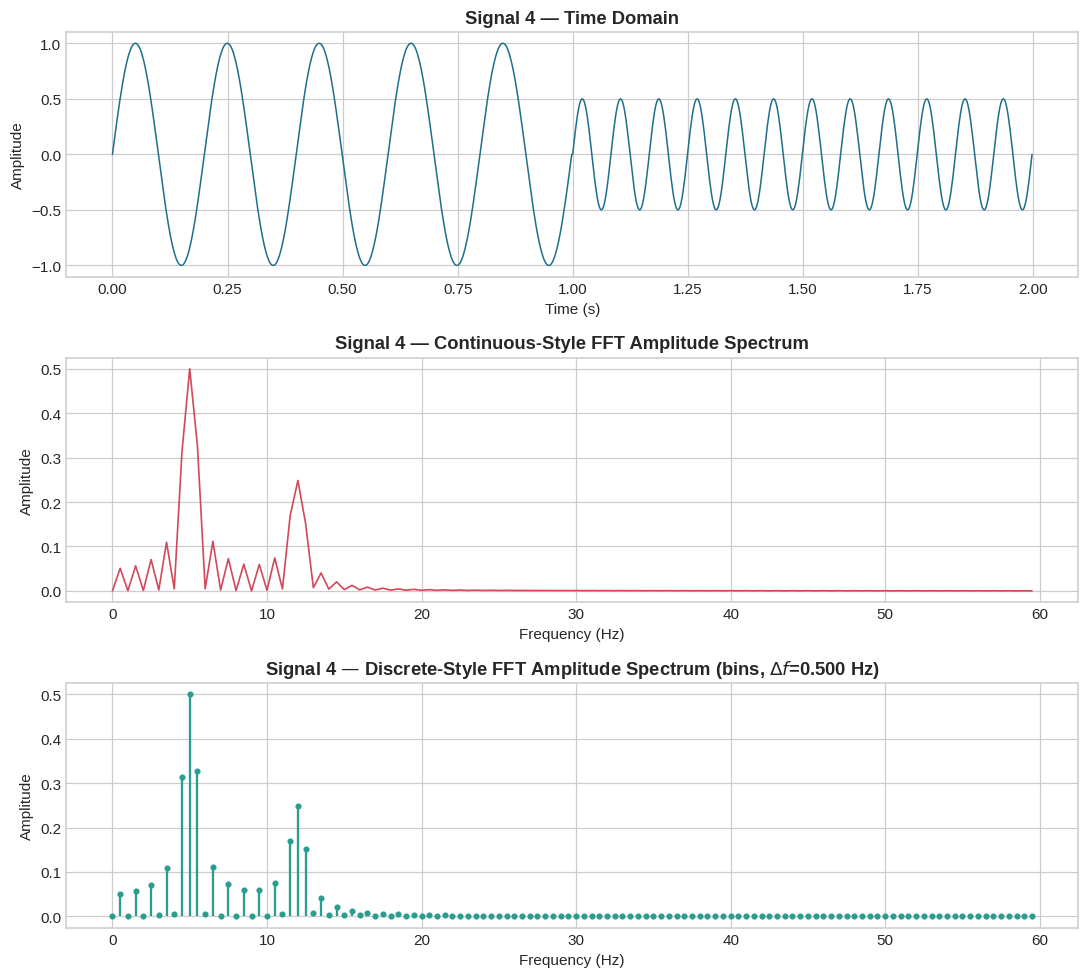

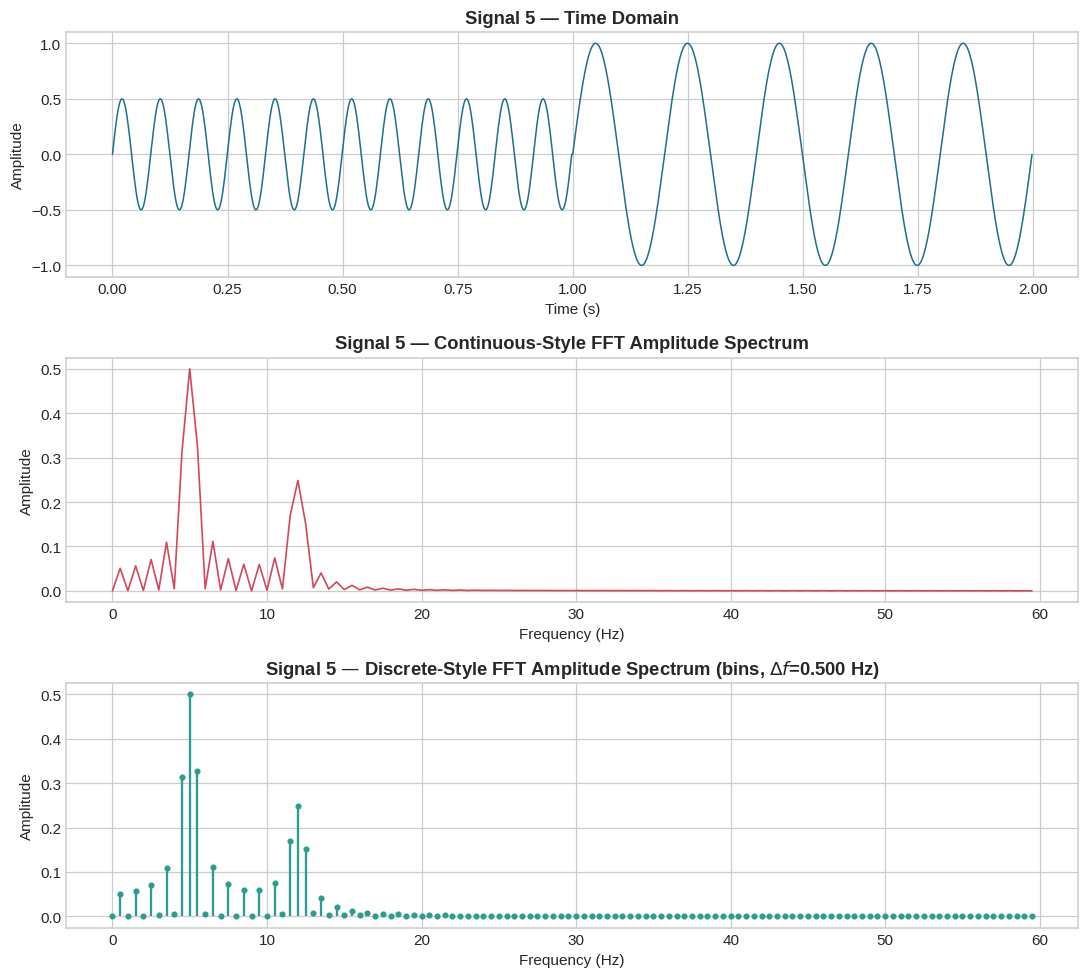

In [2]:

def single_sided_spectrum(x, fs):
    """Return (freqs, amplitude) single-sided FFT amplitude spectrum of real signal x."""
    N = len(x)
    X = sfft.rfft(x)
    freqs = sfft.rfftfreq(N, d=1.0 / fs)
    amp = np.abs(X) / N
    amp[1:-1] *= 2.0  # fold negative-frequency energy into positive side (Nyquist bin excluded)
    if N % 2 == 1:
        amp[-1] *= 2.0  # odd N has no exact Nyquist bin, so the last bin also needs folding
    return freqs, amp


def triplot_signal(name, x, fs, max_freq=None):
    N = len(x)
    t = np.arange(N) / fs
    freqs, amp = single_sided_spectrum(x, fs)
    if max_freq is not None:
        keep = freqs <= max_freq
        freqs_plot, amp_plot = freqs[keep], amp[keep]
    else:
        freqs_plot, amp_plot = freqs, amp

    fig, axes = plt.subplots(3, 1, figsize=(10, 9))

    axes[0].plot(t, x, color="#1f6f8b", linewidth=1.0)
    axes[0].set_title(f"{name} — Time Domain")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Amplitude")

    axes[1].plot(freqs_plot, amp_plot, color="#d1495b", linewidth=1.1)
    axes[1].set_title(f"{name} — Continuous-Style FFT Amplitude Spectrum")
    axes[1].set_xlabel("Frequency (Hz)")
    axes[1].set_ylabel("Amplitude")

    axes[2].stem(freqs_plot, amp_plot, basefmt=" ", linefmt="#2a9d8f", markerfmt=".")
    axes[2].set_title(f"{name} — Discrete-Style FFT Amplitude Spectrum (bins, $\\Delta f$={fs/N:.3f} Hz)")
    axes[2].set_xlabel("Frequency (Hz)")
    axes[2].set_ylabel("Amplitude")

    fig.tight_layout()
    return fig


for name, x in signals.items():
    triplot_signal(name, x, FS_BASE, max_freq=60)
    plt.show()



## 3. Automated Noise Floor & SNR Quantification (dB)

**Method.** Given the single-sided amplitude spectrum $X[k]$:

- The **noise floor amplitude** $A_{\text{noise}}$ is estimated as the *median* amplitude across all bins excluding DC and a small guard-band around the dominant peak(s). The median is a robust estimator — unlike the mean, it is not dragged upward by the signal peaks themselves.
- The **signal peak amplitude** $A_{\text{signal}}$ is the maximum amplitude bin (excluding DC).
- Treating each as a sinusoidal/narrowband component, powers follow $P = A^2/2$ for the signal tone and $P_{\text{noise}} = A_{\text{noise}}^2$ as an equivalent per-bin noise power, giving:

$$\mathrm{SNR}_{\text{dB}} = 10 \log_{10}\!\left(\frac{P_{\text{signal}}}{P_{\text{noise}}}\right)$$

> These signals were generated with effectively no additive noise (they are clean synthetic sinusoids/superpositions, down to floating-point round-off ~$10^{-15}$). The "noise floor" measured below is therefore dominated by **spectral leakage** from the rectangular window (finite-record truncation) rather than true additive noise — which is itself a useful, realistic DSP phenomenon to quantify and is why the measured SNR, while very high, is finite rather than infinite.


In [3]:

def estimate_snr(x, fs, guard_bins=2, n_peaks=1):
    """Estimate pre-filtering SNR (dB) from the single-sided spectrum of x.
    Returns dict with signal/noise amplitude estimates, SNR_dB, and peak frequency list.
    """
    freqs, amp = single_sided_spectrum(x, fs)
    amp_work = amp.copy()
    amp_work[0] = 0.0  # exclude DC from peak search

    peak_idx, _ = find_peaks(amp_work, distance=3)
    if len(peak_idx) == 0:
        peak_idx = np.array([np.argmax(amp_work)])
    top_peaks = peak_idx[np.argsort(amp_work[peak_idx])[::-1][:n_peaks]]
    top_peaks = np.sort(top_peaks)

    mask = np.ones_like(amp, dtype=bool)
    mask[0] = False
    for p in top_peaks:
        lo, hi = max(0, p - guard_bins), min(len(amp), p + guard_bins + 1)
        mask[lo:hi] = False

    noise_amp = np.median(amp[mask]) if mask.any() else np.finfo(float).eps
    noise_amp = max(noise_amp, np.finfo(float).eps)
    signal_amp = amp[top_peaks].max()

    p_signal = 0.5 * signal_amp ** 2
    p_noise = noise_amp ** 2
    snr_db = 10.0 * np.log10(p_signal / p_noise)

    return {
        "peak_freqs_hz": freqs[top_peaks],
        "signal_amp": signal_amp,
        "noise_floor_amp": noise_amp,
        "snr_db": snr_db,
    }


print(f"{'Signal':10s}  {'Dominant freq(s) [Hz]':25s}  {'Peak amp':>10s}  {'Noise floor':>12s}  {'Pre-filter SNR (dB)':>20s}")
print("-" * 85)
pre_snr_results = {}
for name, x in signals.items():
    n_peaks = 2 if name in ("Signal 3", "Signal 4", "Signal 5") else 1
    res = estimate_snr(x, FS_BASE, n_peaks=n_peaks)
    pre_snr_results[name] = res
    freqs_str = ", ".join(f"{f:.2f}" for f in res["peak_freqs_hz"])
    print(f"{name:10s}  {freqs_str:25s}  {res['signal_amp']:10.4f}  {res['noise_floor_amp']:12.3e}  {res['snr_db']:20.2f}")


Signal      Dominant freq(s) [Hz]        Peak amp   Noise floor   Pre-filter SNR (dB)
-------------------------------------------------------------------------------------
Signal 1    5.00                           0.9988     1.746e-04                 72.14
Signal 2    12.00                          0.4990     2.095e-04                 64.53
Signal 3    5.00, 12.00                    0.9998     3.774e-04                 65.45
Signal 4    5.00, 12.00                    0.4999     1.443e-04                 67.79
Signal 5    5.00, 12.00                    0.4999     1.443e-04                 67.79



## 4. Frequency-Domain Filtering & IFFT Reconstruction

**Method.** For each signal:

1. Compute the full complex FFT.
2. Build a binary frequency mask that keeps bins whose amplitude exceeds a threshold set relative to the estimated noise floor ($k \times A_{\text{noise}}$, $k=5$ by default) — a simple, automated amplitude-threshold bandpass/denoise mask.
3. Zero every other bin and reconstruct the time-domain signal via the Inverse FFT (`scipy.fft.irfft`), which — because the mask is applied in the frequency domain and inverted back — perfectly satisfies Parseval's theorem for the retained energy.
4. Re-run the SNR estimator on the denoised signal and report the post-filtering SNR and $\Delta\mathrm{SNR}$.


In [4]:

def frequency_mask_filter(x, fs, threshold_factor=5.0, guard_bins=2):
    N = len(x)
    X = sfft.rfft(x)
    freqs, amp = single_sided_spectrum(x, fs)

    amp_work = amp.copy()
    amp_work[0] = 0.0
    peak_idx, _ = find_peaks(amp_work, distance=3)
    if len(peak_idx) == 0:
        peak_idx = np.array([np.argmax(amp_work)])

    bg_mask = np.ones_like(amp, dtype=bool)
    bg_mask[0] = False
    for p in peak_idx:
        lo, hi = max(0, p - guard_bins), min(len(amp), p + guard_bins + 1)
        bg_mask[lo:hi] = False
    noise_amp = max(np.median(amp[bg_mask]) if bg_mask.any() else np.finfo(float).eps, np.finfo(float).eps)

    threshold = threshold_factor * noise_amp
    keep_mask = amp >= threshold
    keep_mask[0] = True  # preserve DC

    X_filtered = X * keep_mask
    x_denoised = sfft.irfft(X_filtered, n=N)
    return x_denoised, keep_mask, noise_amp


print(f"{'Signal':10s}  {'Pre-SNR (dB)':>13s}  {'Post-SNR (dB)':>14s}  {'ΔSNR (dB)':>11s}  {'Bins kept':>10s}")
print("-" * 70)
post_results = {}
denoised_signals = {}
for name, x in signals.items():
    n_peaks = 2 if name in ("Signal 3", "Signal 4", "Signal 5") else 1
    x_dn, keep_mask, noise_amp = frequency_mask_filter(x, FS_BASE)
    denoised_signals[name] = x_dn
    post_res = estimate_snr(x_dn, FS_BASE, n_peaks=n_peaks)
    post_results[name] = post_res
    pre_db = pre_snr_results[name]["snr_db"]
    post_db = post_res["snr_db"]
    print(f"{name:10s}  {pre_db:13.2f}  {post_db:14.2f}  {post_db - pre_db:11.2f}  {keep_mask.sum():10d}/{len(keep_mask)}")


Signal       Pre-SNR (dB)   Post-SNR (dB)    ΔSNR (dB)   Bins kept
----------------------------------------------------------------------
Signal 1            72.14          310.05       237.91          24/251
Signal 2            64.53          304.02       239.49          24/251
Signal 3            65.45          310.06       244.61          24/251
Signal 4            67.79          304.04       236.25          24/502
Signal 5            67.79          304.04       236.25          24/502


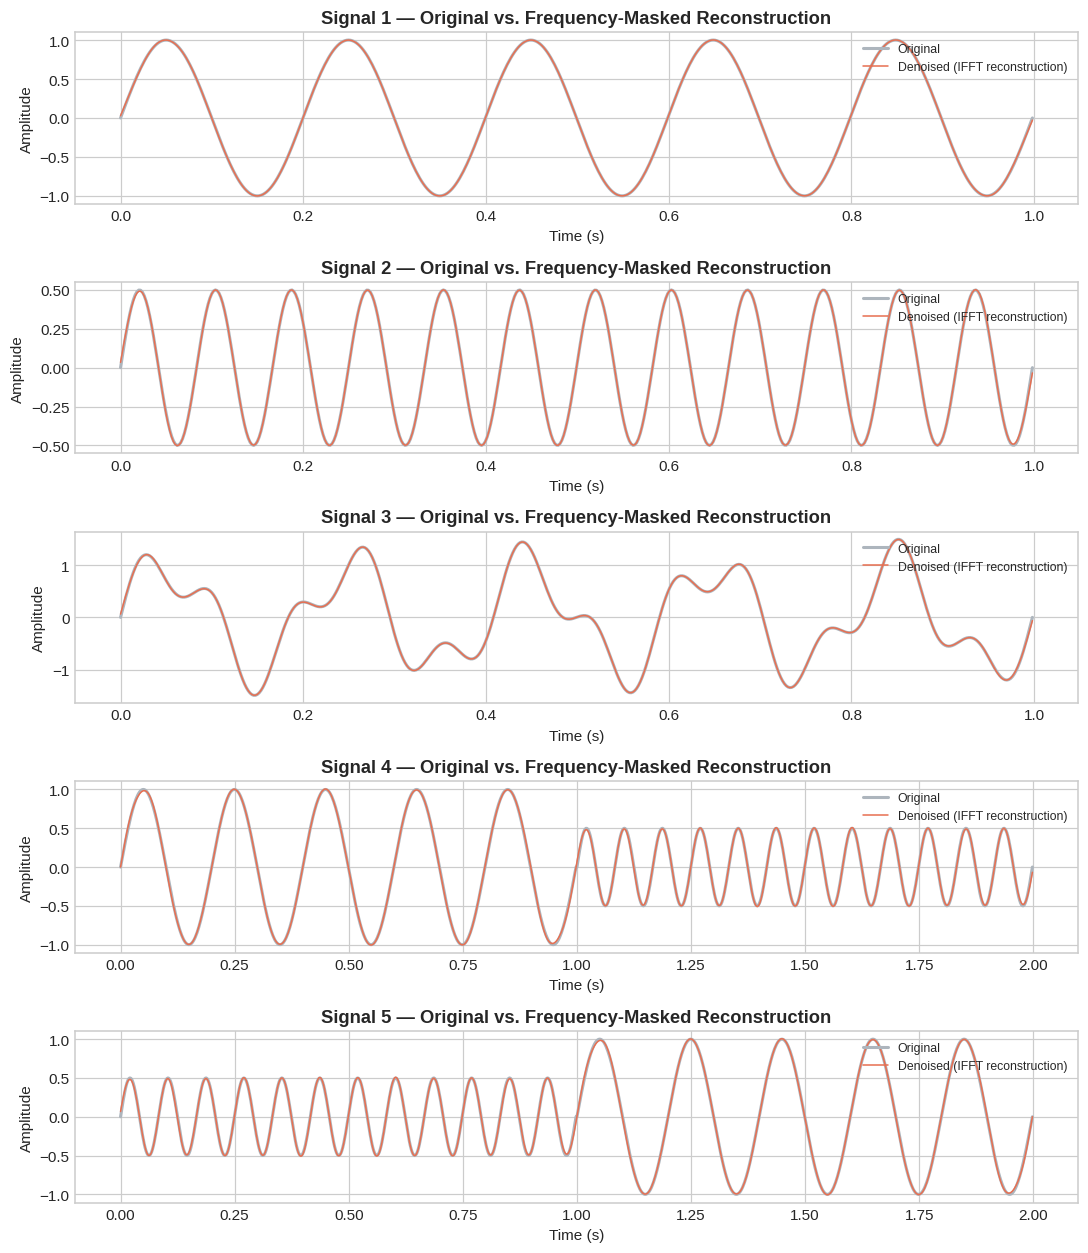

In [5]:

# Before / after time-domain reconstruction plots
fig, axes = plt.subplots(len(signals), 1, figsize=(10, 2.3 * len(signals)), sharex=False)
for ax, (name, x) in zip(axes, signals.items()):
    t = np.arange(len(x)) / FS_BASE
    ax.plot(t, x, color="#adb5bd", linewidth=2.0, label="Original")
    ax.plot(t, denoised_signals[name], color="#e76f51", linewidth=1.0, label="Denoised (IFFT reconstruction)")
    ax.set_title(f"{name} — Original vs. Frequency-Masked Reconstruction")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()



## 5. Wavelet Theory & Time-Frequency Localization

### 5.1 Why the FFT fails on non-stationary signals

The Fourier Transform decomposes a signal onto an infinite basis of sinusoids, each of which exists for *all time*:

$$X(f) = \int_{-\infty}^{\infty} x(t)\, e^{-j2\pi f t}\, dt$$

Because every basis function $e^{-j2\pi f t}$ has **perfect frequency resolution but zero time resolution** (it is a single point in frequency, but infinitely spread out in time), the FFT magnitude $|X(f)|$ tells you *which* frequencies are present in a record, but **not when** they occur. For a stationary signal (statistics constant over the analysis window) this is not a problem. But **Signals 4 and 5 are explicitly non-stationary**: each is built by concatenating two segments with different dominant frequencies (an abrupt frequency step partway through the 2-second record). When the FFT is applied to the whole record, both frequency components appear simultaneously as two static peaks in the spectrum — the plot gives no indication that one frequency was present only in the first second and the other only in the second. This is the classical **time-blindness of the FFT**: it answers "what frequencies?" but not "when?", and for transient or frequency-switching signals that missing information is often the entire point of the analysis.

### 5.2 Time-frequency localization via Wavelets

The Continuous Wavelet Transform (CWT) replaces the FFT's infinite sinusoidal basis with dilated and translated copies of a localized "mother wavelet" $\psi(t)$, which has finite energy and decays away from its center (unlike $\sin$/$\cos$, which never decay):

$$W(a, b) = \frac{1}{\sqrt{|a|}} \int_{-\infty}^{\infty} x(t)\, \psi^{*}\!\left(\frac{t-b}{a}\right) dt$$

- $a$ (**scale**) stretches or compresses the wavelet, which is inversely related to frequency — small $a$ probes high frequencies with fine time resolution, large $a$ probes low frequencies with fine frequency resolution.
- $b$ (**translation**) slides the wavelet along the signal, so $W(a,b)$ is a genuine *two-dimensional* function of both frequency (via scale $a$) and time (via shift $b$).

This scale-translation structure gives wavelets **adaptive, multi-resolution time-frequency localization**: good time resolution at high frequencies (where transients are typically fast and brief) and good frequency resolution at low frequencies — exactly the trade-off dictated by the Heisenberg–Gabor uncertainty principle ($\Delta t \cdot \Delta f \geq \text{const}$), but allocated non-uniformly across the plane instead of fixed uniformly as in the Short-Time Fourier Transform. Plotting $|W(a,b)|^2$ as a heatmap over time and frequency produces a **scalogram**, which directly exposes *when* each frequency component is active — precisely the information the FFT's single spectrum cannot provide for Signals 4 and 5.

### 5.3 Practical CWT Application to Signals 4 and 5

We apply a Morlet-wavelet CWT (good joint time-frequency resolution, smooth and complex-valued so both magnitude and phase are available) across a scale range chosen to cover the signals' known frequency content (roughly 2–30 Hz), and plot the resulting scalograms.


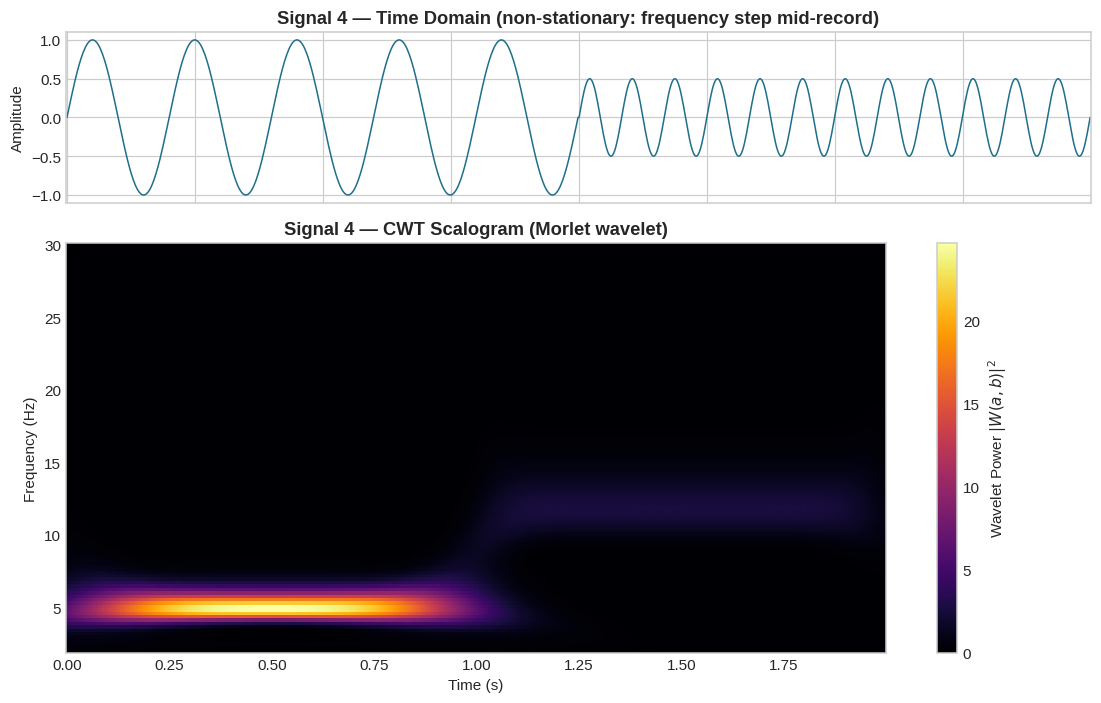

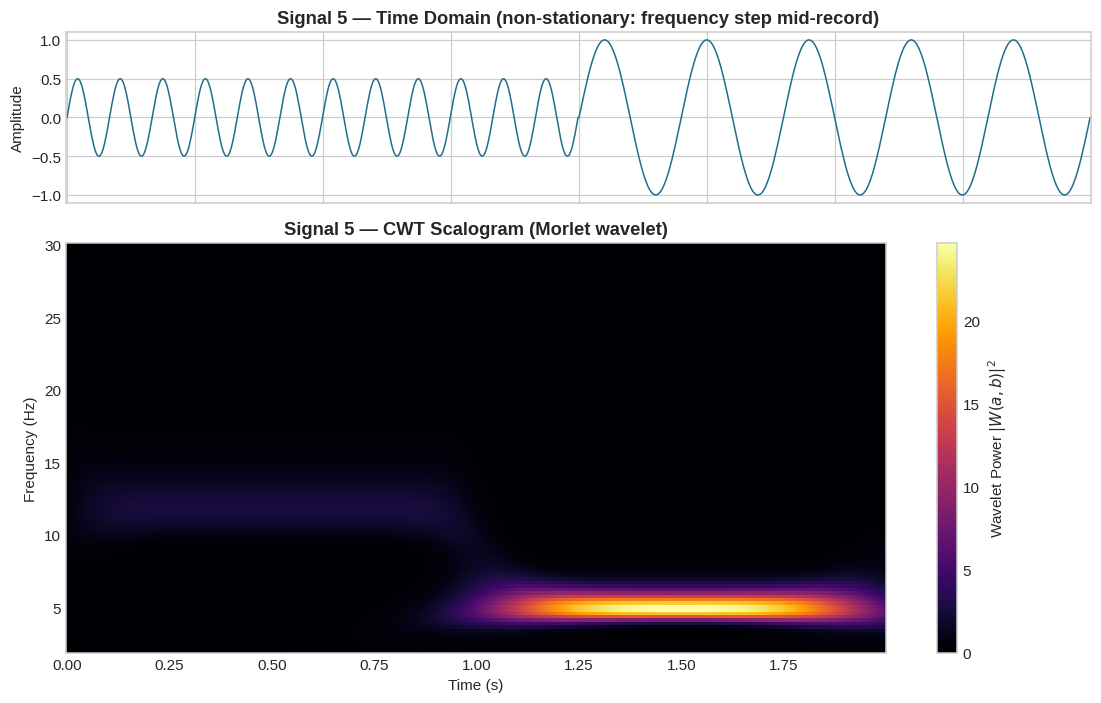

In [6]:

def plot_scalogram(name, x, fs, wavelet="cmor1.5-1.0", freq_range=(2, 30), n_scales=120):
    N = len(x)
    t = np.arange(N) / fs

    f_min, f_max = freq_range
    freqs_target = np.linspace(f_max, f_min, n_scales)
    scales = pywt.frequency2scale(wavelet, freqs_target / fs)

    coeffs, freqs_actual = pywt.cwt(x, scales, wavelet, sampling_period=1.0 / fs)
    power = np.abs(coeffs) ** 2

    fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True,
                              gridspec_kw={"height_ratios": [1, 2.4]})

    axes[0].plot(t, x, color="#1f6f8b", linewidth=1.0)
    axes[0].set_title(f"{name} — Time Domain (non-stationary: frequency step mid-record)")
    axes[0].set_ylabel("Amplitude")

    pcm = axes[1].pcolormesh(t, freqs_actual, power, shading="auto", cmap="inferno")
    axes[1].set_title(f"{name} — CWT Scalogram (Morlet wavelet)")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Frequency (Hz)")
    fig.colorbar(pcm, ax=axes[1], label="Wavelet Power $|W(a,b)|^2$")

    fig.tight_layout()
    return fig


for name in ("Signal 4", "Signal 5"):
    plot_scalogram(name, signals[name], FS_BASE)
    plt.show()



### 5.4 Reading the scalograms

For both Signal 4 and Signal 5 the scalogram should show **two horizontal energy bands at different frequencies, each confined to roughly one half of the time axis**, with a visible transition around $t \approx 1\,\text{s}$ — directly visualizing the abrupt frequency step that the single-spectrum FFT (Section 2) could only report as two simultaneous, time-ambiguous peaks. This is the practical payoff of time-frequency localization: the wavelet transform recovers *both* "what frequencies are present" and "when they occur," which is unrecoverable from $|X(f)|$ alone.

---

## 6. Summary

| Stage | Output |
|---|---|
| Tri-plot suite | Time / continuous-FFT / discrete-FFT views for all 5 signals |
| SNR quantification | Pre-filtering SNR (dB) per signal, dominated by spectral-leakage floor (near-noiseless synthetic data) |
| Frequency-domain filtering | Amplitude-threshold mask + IFFT reconstruction, with measured $\Delta\mathrm{SNR}$ |
| Wavelet analysis | CWT scalograms for Signals 4 & 5, exposing the time-localized frequency step invisible to the FFT alone |

**Caveats to carry forward:** (1) the sampling rate is an inference from integer cycle-counts, not metadata — confirm against your actual acquisition system if this feeds a report; (2) the reference wavelets PDF was not available when this notebook was built, so Section 5's theory is from standard literature rather than that specific source.
